# Modelação — Agrupamento Não Supervisionado (Clustering)
**Identificação de Perfis Fisiológicos Exploratórios Neonatais**

Metodologia: **CRISP-DM — Fase 4: Modelação (Não Supervisionada)**  
Objetivo de Negócio associado: **ON1 — Estratificar o perfil dos doentes internados**  
Objetivo de Mineração de Dados: **ODM1 — Identificar subgrupos naturais de episódios com base no perfil fisiológico**

| Ficheiro lido | Produzido por | Conteúdo |
|---|---|---|
| `03_data_preparation/dataset_final.csv` | `data_preparation.ipynb` | 47 episódios com features fisiológicas consolidadas |


In [1]:
import csv
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

%matplotlib inline

DATA_DIR = Path("../03_data_preparation")

with open(DATA_DIR / "dataset_final.csv", newline="", encoding="utf-8") as f:
    df_final = list(csv.DictReader(f))

FEATURE_COLS = [
    "sat_o2_mean", "sat_o2_std", "sat_o2_min", "sat_o2_max",
    "puls_rate_mean", "puls_rate_std", "puls_rate_min", "puls_rate_max",
    "perfusion_mean", "perfusion_std", "perfusion_min", "perfusion_max",
    "desat_count", "desat_pct"
]

X_raw = np.array([[float(r[c]) for c in FEATURE_COLS] for r in df_final])
ep_ids = [r["episodio"] for r in df_final]

print(f"Episódios carregados: {len(X_raw)}")
print(f"Features fisiológicas utilizadas ({len(FEATURE_COLS)}):")
for c in FEATURE_COLS:
    print(f"  - {c}")


Episódios carregados: 47
Features fisiológicas utilizadas (14):
  - sat_o2_mean
  - sat_o2_std
  - sat_o2_min
  - sat_o2_max
  - puls_rate_mean
  - puls_rate_std
  - puls_rate_min
  - puls_rate_max
  - perfusion_mean
  - perfusion_std
  - perfusion_min
  - perfusion_max
  - desat_count
  - desat_pct


## 1. Padronização e Análise de Componentes Principais (PCA)

Como os sinais vitais operam em escalas distintas (SpO₂ em %, FC em bpm, perfusão em %), a padronização Z-score é obrigatória para evitar que variáveis com maior dispersão dominem o cálculo das distâncias euclidianas.


In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

print(f"Variância explicada pelo PC1: {var_exp[0]*100:.1f}%")
print(f"Variância explicada pelo PC2: {var_exp[1]*100:.1f}%")
print(f"Variância total retida (2 componentes): {sum(var_exp)*100:.1f}%")


Variância explicada pelo PC1: 29.7%
Variância explicada pelo PC2: 19.3%
Variância total retida (2 componentes): 49.0%


## 2. Seleção do Número de Clusters (k-Means)

Avaliação de k ∈ [2, 5] através do Índice de Silhueta (quanto maior, melhor) e Índice de Davies-Bouldin (quanto menor, melhor).


k        Inércia      Silhueta    Davies-Bouldin
------------------------------------------------
2         531.16        0.2263            1.6246
3         444.58        0.1918            1.5813
4         381.70        0.1792            1.4352
5         335.63        0.1448            1.4155


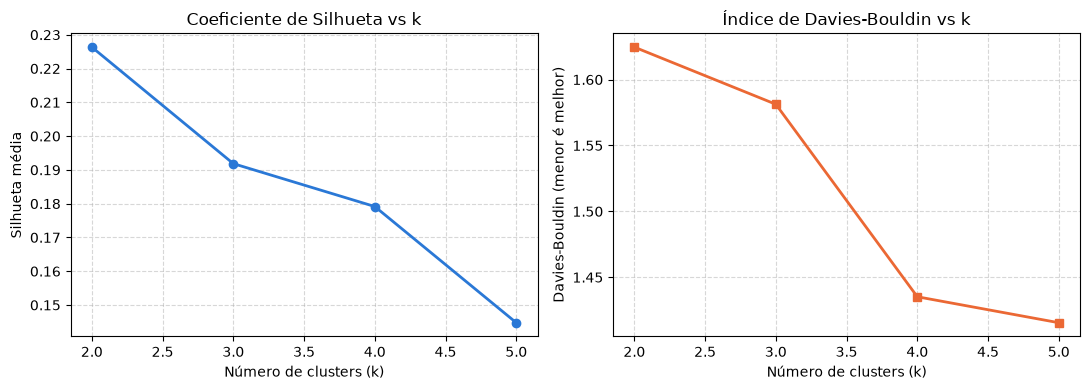

In [3]:
k_range = range(2, 6)
sil_scores = []
db_scores = []
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    sil_scores.append(sil)
    db_scores.append(db)
    inertias.append(km.inertia_)

print(f"{'k':<4}  {'Inércia':>10}  {'Silhueta':>12}  {'Davies-Bouldin':>16}")
print("-" * 48)
for k, inr, sil, db in zip(k_range, inertias, sil_scores, db_scores):
    print(f"{k:<4}  {inr:>10.2f}  {sil:>12.4f}  {db:>16.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_range, sil_scores, marker='o', color='#2a78d6', lw=2)
axes[0].set_title("Coeficiente de Silhueta vs k")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Silhueta média")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(k_range, db_scores, marker='s', color='#eb6834', lw=2)
axes[1].set_title("Índice de Davies-Bouldin vs k")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Davies-Bouldin (menor é melhor)")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## 3. Modelo Final de Clustering e Caracterização Descritiva dos Perfis

Seleciona-se k=2 como solução de maior coesão/separabilidade relativa para particionamento exploratório dos perfis fisiológicos.

> **Ressalva Metodológica:** Os clusters representam agrupamentos estatísticos exploratórios obtidos através do algoritmo k-Means. A separação observada é modesta (Silhueta = 0.2263), pelo que os perfis identificados não devem ser interpretados como diagnósticos clínicos, categorias de risco validadas ou indicadores autónomos de estabilidade clínica.


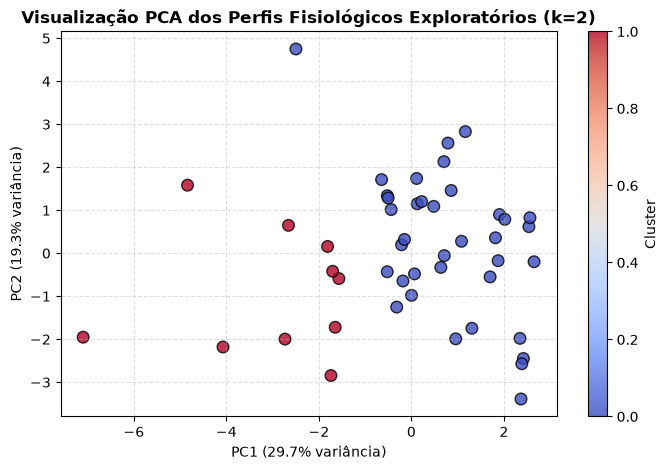

Caracterização descritiva dos clusters formados:

Cluster 0 — Perfil com saturação média mais elevada (n=37 episódios, 78.7%):
  SpO2 média:           96.66%
  Frequência Cardíaca:  138.9 bpm
  Índice de Perfusão:   1.22
  % Dessaturação média: 0.09%

Cluster 1 — Perfil com maior frequência de dessaturações (n=10 episódios, 21.3%):
  SpO2 média:           94.86%
  Frequência Cardíaca:  152.8 bpm
  Índice de Perfusão:   1.12
  % Dessaturação média: 2.56%

--- Conclusões Metodológicas ---
1. O agrupamento particiona os dados em dois perfis descritivos: um grupo com saturação média mais elevada (Cluster 0, 78.7%) e um grupo com maior frequência de dessaturações (Cluster 1, 21.3%).
2. Ressalva Metodológica: Os clusters representam agrupamentos estatísticos exploratórios obtidos através do algoritmo k-Means. A separação observada é modesta (Silhueta = 0.2263), pelo que os perfis identificados não devem ser interpretados como diagnósticos clínicos, categorias de risco validadas ou indicadore

In [4]:
k_opt = 2
km_final = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
cluster_labels = km_final.fit_predict(X_scaled)

fig, ax = plt.subplots(figsize=(8, 5))
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap="coolwarm", s=70, edgecolors='k', alpha=0.8)
ax.set_title(f"Visualização PCA dos Perfis Fisiológicos Exploratórios (k={k_opt})", fontsize=12, fontweight="bold")
ax.set_xlabel(f"PC1 ({var_exp[0]*100:.1f}% variância)")
ax.set_ylabel(f"PC2 ({var_exp[1]*100:.1f}% variância)")
plt.colorbar(scatter, ax=ax, label="Cluster")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# Nomes descritivos associados empiricamente às médias calculadas de cada cluster
cluster_names = {
    0: "Perfil com saturação média mais elevada",
    1: "Perfil com maior frequência de dessaturações"
}

print("Caracterização descritiva dos clusters formados:")
for c_idx in range(k_opt):
    mask = (cluster_labels == c_idx)
    n_c = int(np.sum(mask))
    spo2_m = np.mean(X_raw[mask, FEATURE_COLS.index("sat_o2_mean")])
    fc_m   = np.mean(X_raw[mask, FEATURE_COLS.index("puls_rate_mean")])
    perf_m = np.mean(X_raw[mask, FEATURE_COLS.index("perfusion_mean")])
    desat_p= np.mean(X_raw[mask, FEATURE_COLS.index("desat_pct")])
    
    print(f"\nCluster {c_idx} — {cluster_names[c_idx]} (n={n_c} episódios, {n_c/len(X_raw)*100:.1f}%):")
    print(f"  SpO2 média:           {spo2_m:.2f}%")
    print(f"  Frequência Cardíaca:  {fc_m:.1f} bpm")
    print(f"  Índice de Perfusão:   {perf_m:.2f}")
    print(f"  % Dessaturação média: {desat_p:.2f}%")

print("\n--- Conclusões Metodológicas ---")
print("1. O agrupamento particiona os dados em dois perfis descritivos: um grupo com saturação média mais elevada (Cluster 0, 78.7%) e um grupo com maior frequência de dessaturações (Cluster 1, 21.3%).")
print("2. Ressalva Metodológica: Os clusters representam agrupamentos estatísticos exploratórios obtidos através do algoritmo k-Means. A separação observada é modesta (Silhueta = 0.2263), pelo que os perfis identificados não devem ser interpretados como diagnósticos clínicos, categorias de risco validadas ou indicadores autónomos de estabilidade clínica.")
print("3. Limitação: dimensão amostral reduzida (n=47 episódios) recomenda que a estrutura seja tratada como estritamente preliminar e exploratória.")